# Data distribution experiments

# My Custom Experiments

In the previous sections I have attempted to re-produce experiments from Gatmiry et al. In the following sections, I will implement several experiments that apply different assumptions and test the theoretical bounds of this paper. These were not written in the original paper.

In [1]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from linear_transformer import DataMode
from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_dist_dict,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


# Different Data Distributions

Train the shared-weight looped transformers from the first experiment independently on each configured data mode, then evaluate each set of checkpoints on an independently sampled test batch from that same mode. The seeds, loop counts, optimization settings, and model setup match the first experiment; the gamma shape parameter comes from the problem-parameter cell.

In [4]:
# Add data mode as an independent experiment configuration.
gamma_data_mode_low_shape = DataMode("gamma", gamma_shape=0.1, gamma_scale=1)
gamma_data_mode_high_shape = DataMode("gamma", gamma_shape=5, gamma_scale=1)
t_distribution_mode = DataMode("t", t_degrees_freedom=5)

seeds = [0]
loop_counts = [5]
model_types = ['looped']
context_lengths = [N]
data_modes = [normal_data_mode, gamma_data_mode_low_shape, gamma_data_mode_high_shape, t_distribution_mode]
iterations = np.arange(0, max_iters, stride)

gamma_fig_dir = os.path.join('figures', 'data_mode_comparison')
os.makedirs(gamma_fig_dir, exist_ok=True)

gamma_history_file = os.path.join(
    cur_dir, f'data_modes_normal_gamma_N{N}_d{d}_histories.pth')
gamma_results_file = os.path.join(
    cur_dir, f'data_modes_normal_gamma_N{N}_d{d}_results.pth')

gamma_hist_dict = run_experiment_suite(
    seeds=seeds,
    n_layers_loops=loop_counts,
    model_types=model_types,
    filename=gamma_history_file,
    context_lengths=context_lengths,
    data_modes=data_modes,
    freeze_p=True,  # [P-FIX] paper's P = [[0, 0], [0, 1]]
)

gamma_loss_dict = {
    test_data_mode: compute_loss_dict(
        gamma_hist_dict,
        test_seed=TEST_SEED,
        data_mode=test_data_mode,
    )
    for test_data_mode in data_modes
}
# Parameter distances depend on the trained checkpoints, not on the test data mode.
gamma_dist_dict = compute_dist_dict(
    gamma_hist_dict, iterations, n_head, hist_stride=hist_stride)


Run 1/4: seed=0, count=5, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear, freeze_p=True
iter 0 | Loss: 17.92928123474121 | time: 0.013445138931274414 | gradnorm: 165.81643676757812
iter 1 | Loss: 14.664645195007324 | time: 0.012591361999511719 | gradnorm: 124.70455169677734
iter 2 | Loss: 13.553898811340332 | time: 0.01421499252319336 | gradnorm: 110.50276184082031
iter 3 | Loss: 12.8226900100708 | time: 0.013800621032714844 | gradnorm: 102.61194610595703
iter 4 | Loss: 13.936625480651855 | time: 0.013755321502685547 | gradnorm: 120.3150405883789
iter 100 | Loss: 3.549886703491211 | time: 0.01381230354309082 | gradnorm: 21.042280197143555
iter 200 | Loss: 1.917795181274414 | time: 0.013824939727783203 | gradnorm: 7.704891681671143
iter 300 | Loss: 1.1881790161132812 | time: 0.00820612907409668 | gradnorm: 3.0408756732940674
iter 400 | Loss: 0.8246211409568787 | time: 0.013840436935424805 | gradnorm:

Saved data-mode experiment results to log/data_modes_normal_gamma_N10_d5_results.pth


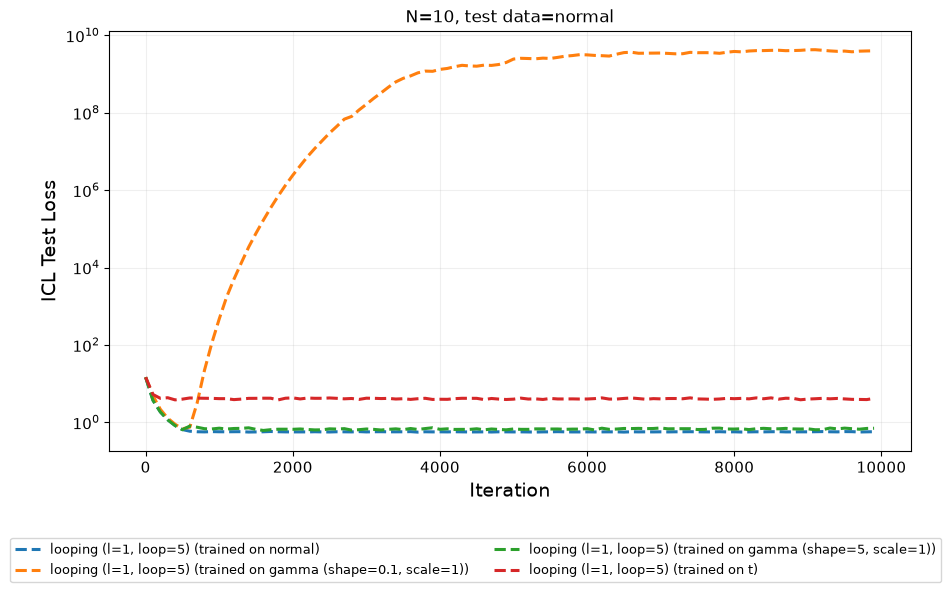

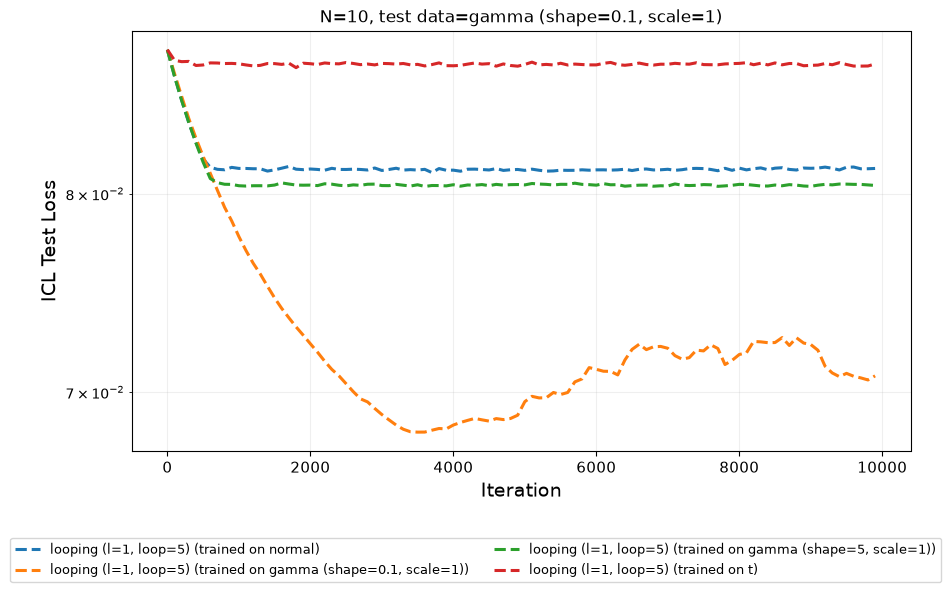

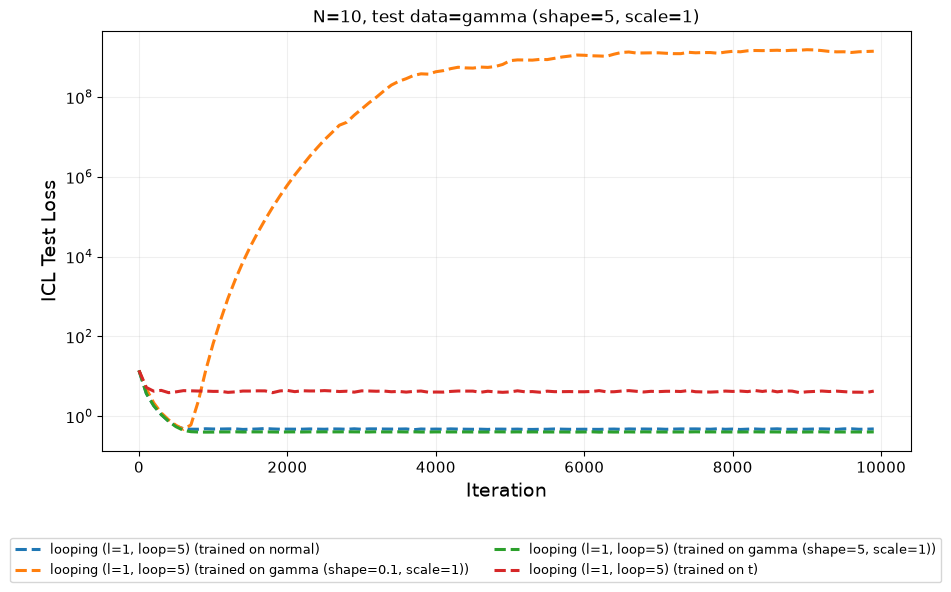

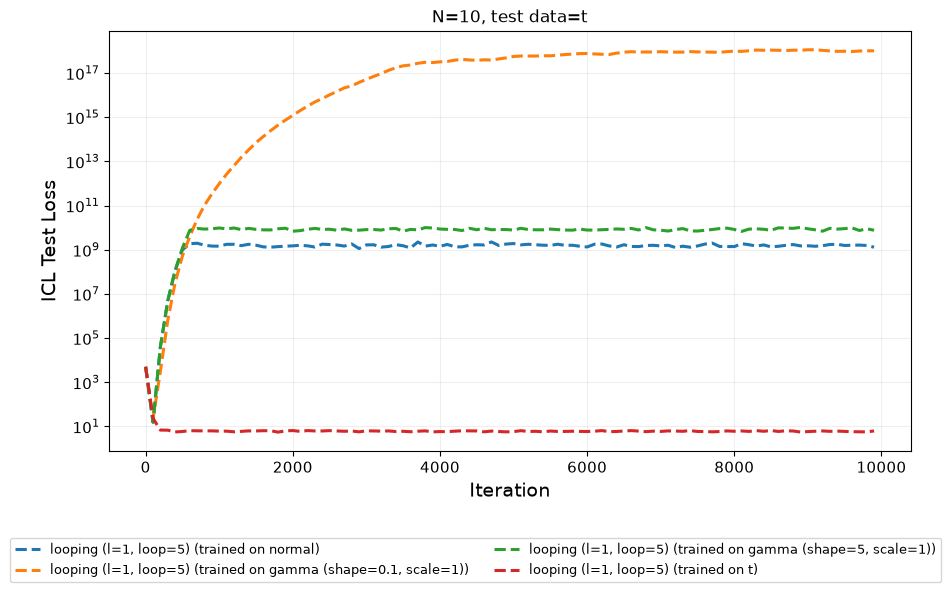

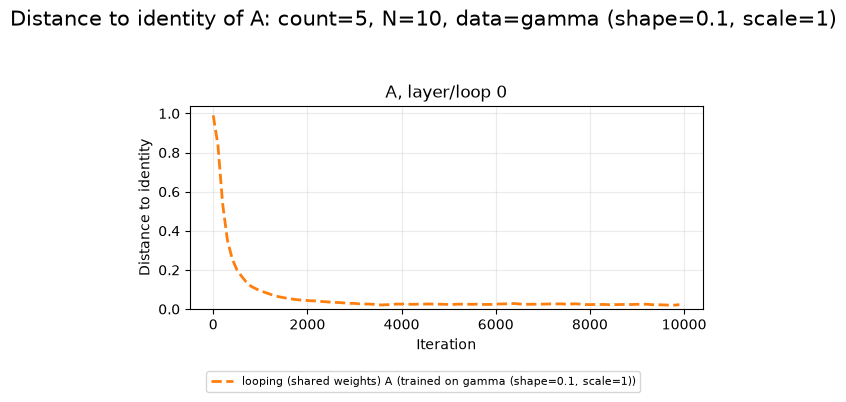

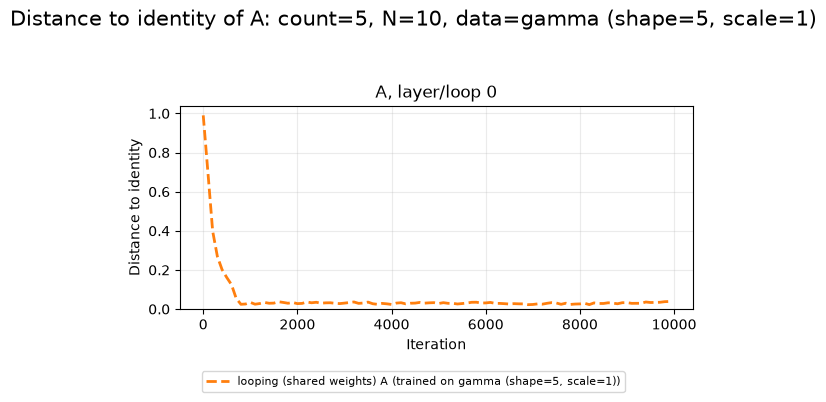

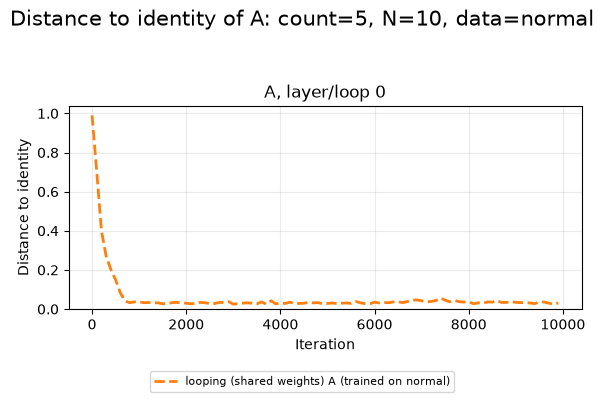

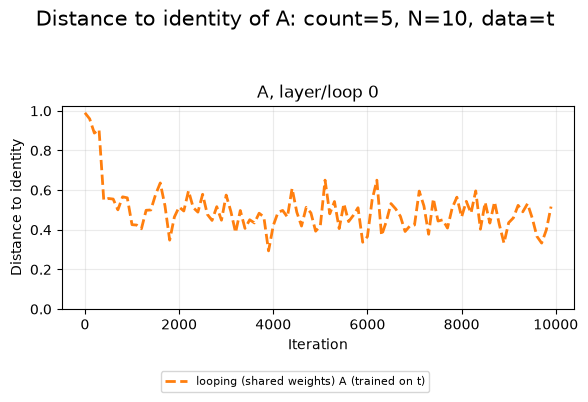

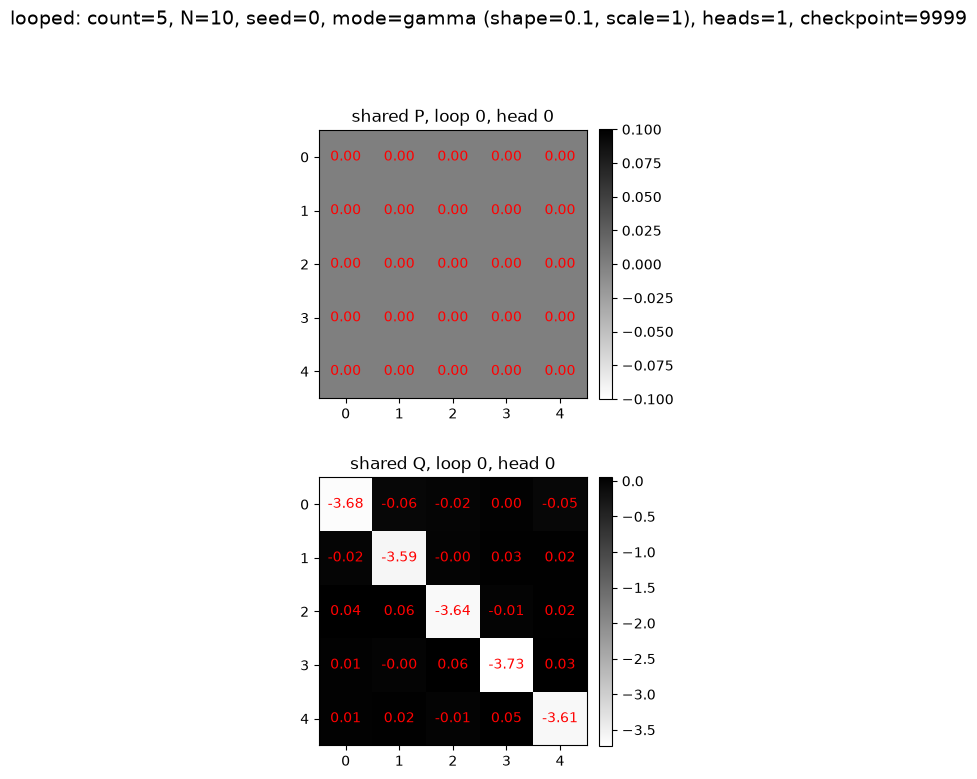

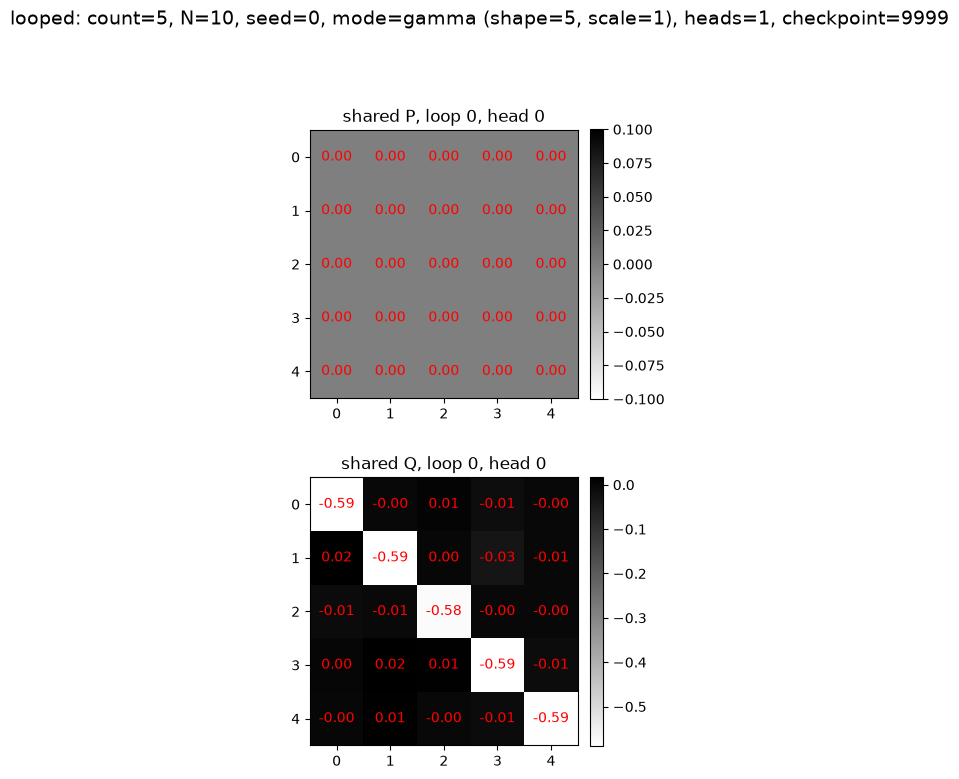

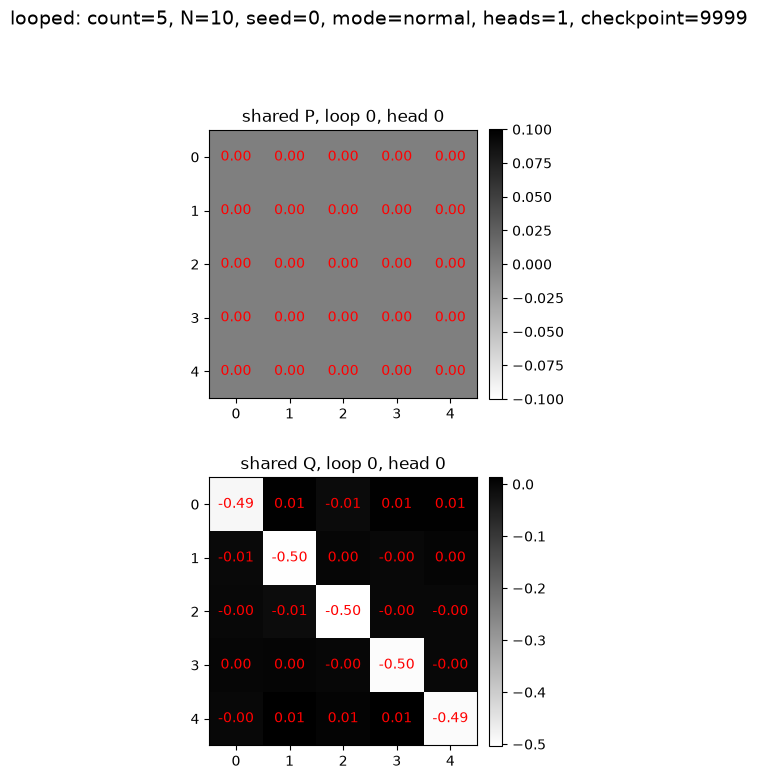

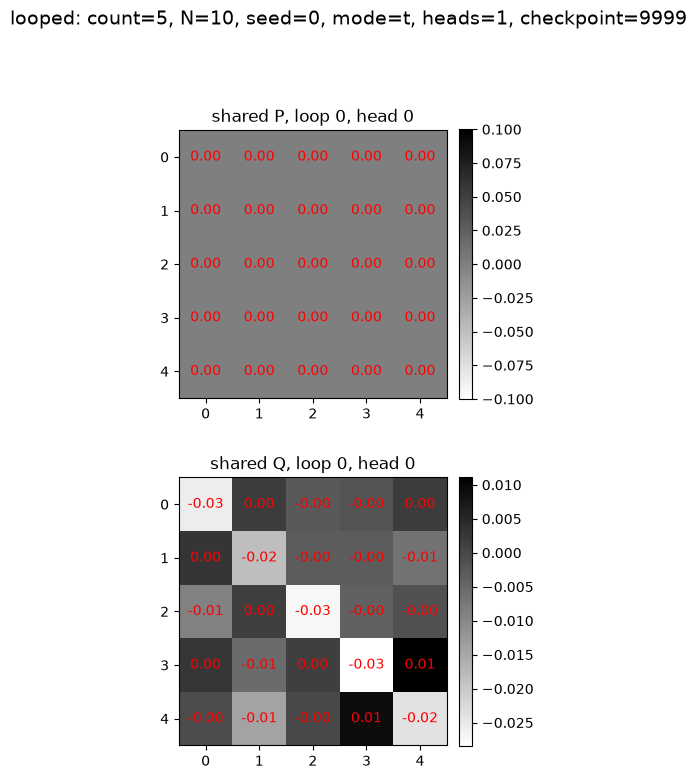

In [5]:
torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'data_modes': data_modes,
        'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': seeds, 'loop_counts': loop_counts,
        'model_types': model_types, 'test_seed': TEST_SEED,
    },
    'history_file': gamma_history_file,
    'hist_dict': gamma_hist_dict,
    'loss_dict_by_test_mode': gamma_loss_dict,
    'distance_dict': gamma_dist_dict,
    'iterations': iterations,
}, gamma_results_file)
print(f'Saved data-mode experiment results to {gamma_results_file}')

for test_data_mode, loss_dict in gamma_loss_dict.items():
    plot_loss_curves(
        loss_dict, loop_counts, model_types, iterations,
        fig_dir=gamma_fig_dir, filename='data_mode_test_loss.pdf',
        test_data_mode=test_data_mode,
    )
plot_dist_to_identity(
    gamma_dist_dict, loop_counts, iterations, fig_dir=gamma_fig_dir,
)
plot_parameter_matrices(
    gamma_hist_dict, seeds[0], loop_counts, model_types, n_head,
    hist_stride=hist_stride, fig_dir=gamma_fig_dir,
)


# Non-Linear Distribution Test

Train the shared-weight looped transformers independently on normal, ReLU-generated, and MLP-generated data. This mirrors the different-distribution experiment: the same seeds, loop counts, optimization settings, and plots are reused to check whether the training converges and to display the learned parameter trajectories.


In [14]:
relu_data_mode = DataMode("relu")
mlp_data_mode = DataMode("mlp")

seeds = [0]
loop_counts = [2, 5, 10]
model_types = ['looped']
context_lengths = [N]
nonlinear_data_modes = [normal_data_mode, relu_data_mode, mlp_data_mode]
iterations = np.arange(0, max_iters, stride)

nonlinear_fig_dir = os.path.join('figures', 'nonlinear_data_mode_comparison')
os.makedirs(nonlinear_fig_dir, exist_ok=True)

nonlinear_history_file = os.path.join(
    cur_dir, f'nonlinear_data_modes_N{N}_d{d}_histories.pth')
nonlinear_results_file = os.path.join(
    cur_dir, f'nonlinear_data_modes_N{N}_d{d}_results.pth')

nonlinear_hist_dict = run_experiment_suite(
    seeds=seeds,
    n_layers_loops=loop_counts,
    model_types=model_types,
    filename=nonlinear_history_file,
    context_lengths=context_lengths,
    data_modes=nonlinear_data_modes,
    freeze_p=True,  # [P-FIX] paper's P = [[0, 0], [0, 1]]
)

nonlinear_loss_dict = {
    test_data_mode: compute_loss_dict(
        nonlinear_hist_dict,
        test_seed=TEST_SEED,
        data_mode=test_data_mode,
    )
    for test_data_mode in nonlinear_data_modes
}
nonlinear_dist_dict = compute_dist_dict(
    nonlinear_hist_dict, iterations, n_head, hist_stride=hist_stride)

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'data_modes': nonlinear_data_modes,
        'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': seeds, 'loop_counts': loop_counts,
        'model_types': model_types, 'test_seed': TEST_SEED,
    },
    'history_file': nonlinear_history_file,
    'hist_dict': nonlinear_hist_dict,
    'loss_dict_by_test_mode': nonlinear_loss_dict,
    'distance_dict': nonlinear_dist_dict,
    'iterations': iterations,
}, nonlinear_results_file)
print(f'Saved non-linear data-mode experiment results to {nonlinear_results_file}')

Run 1/9: seed=0, count=2, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None)
iter 0 | Loss: 5.184084415435791 | time: 0.008438587188720703 | gradnorm: 6.713540554046631
iter 1 | Loss: 4.863616943359375 | time: 0.007271766662597656 | gradnorm: 6.63913631439209
iter 2 | Loss: 5.026864528656006 | time: 0.007939815521240234 | gradnorm: 6.909933567047119
iter 3 | Loss: 4.822576522827148 | time: 0.0077419281005859375 | gradnorm: 6.9354119300842285
iter 4 | Loss: 4.920429229736328 | time: 0.007574796676635742 | gradnorm: 7.037217617034912
iter 100 | Loss: 3.4544289112091064 | time: 0.0052394866943359375 | gradnorm: 5.220376491546631
iter 200 | Loss: 2.650038242340088 | time: 0.006361246109008789 | gradnorm: 3.9534597396850586
iter 300 | Loss: 1.97808039188385 | time: 0.00635838508605957 | gradnorm: 2.7030904293060303
iter 400 | Loss: 1.5920723676681519 | time: 0.004073381423950195 | gradnorm: 1.5670084953308105
iter 500 | Loss: 1.440165

/home/i4sincla/Documents/projects/cs-886/looped-transformers-gradient-descent/.env/lib/python3.12/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


iter 0 | Loss: 22.86710548400879 | time: 2.4036972522735596 | gradnorm: 20.595840454101562
iter 1 | Loss: 11.965705871582031 | time: 0.007816553115844727 | gradnorm: 82.57300567626953
iter 2 | Loss: 23.663801193237305 | time: 0.008239269256591797 | gradnorm: 134.87745666503906
iter 3 | Loss: 22.301246643066406 | time: 0.008141279220581055 | gradnorm: 99.23126220703125
iter 4 | Loss: 18.46664047241211 | time: 0.008145332336425781 | gradnorm: 49.724632263183594
iter 100 | Loss: 15.3301362991333 | time: 0.009746551513671875 | gradnorm: 77.91268920898438
iter 200 | Loss: 6.315530776977539 | time: 0.009783744812011719 | gradnorm: 40.39655685424805
iter 300 | Loss: 7.328475475311279 | time: 0.009759187698364258 | gradnorm: 186.7466278076172
iter 400 | Loss: 7.566160678863525 | time: 0.006357908248901367 | gradnorm: 138.25709533691406
iter 500 | Loss: 6.108644008636475 | time: 0.006046772003173828 | gradnorm: 53.359413146972656
iter 600 | Loss: 6.221442699432373 | time: 0.006385087966918945 |

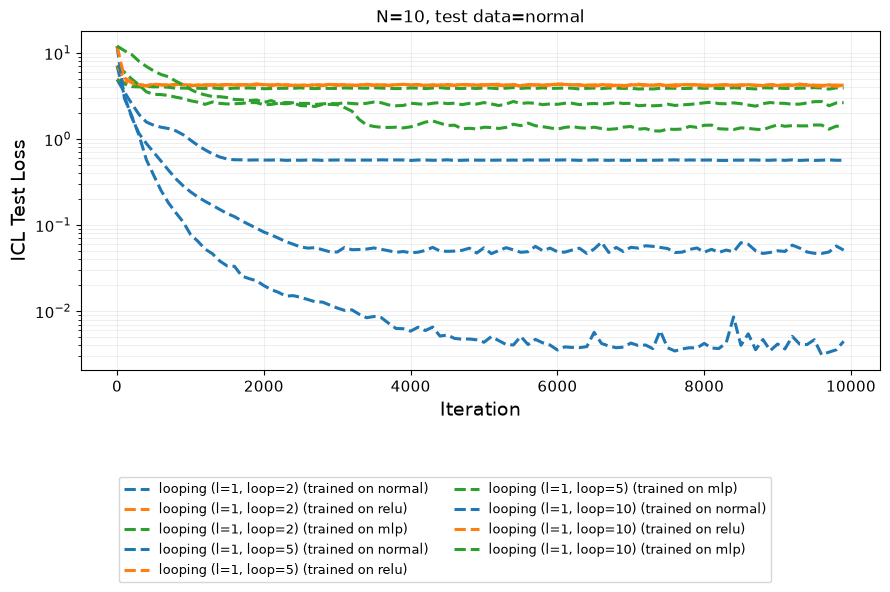

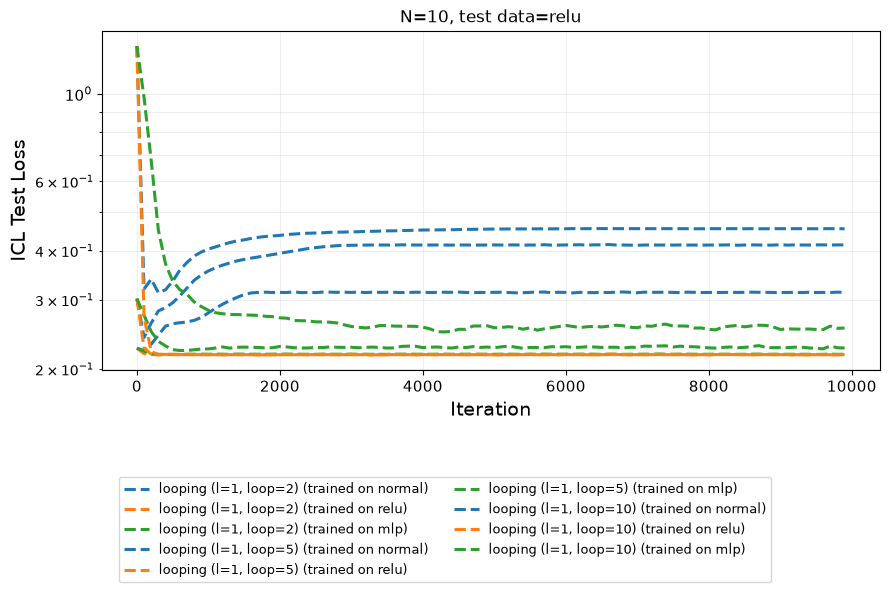

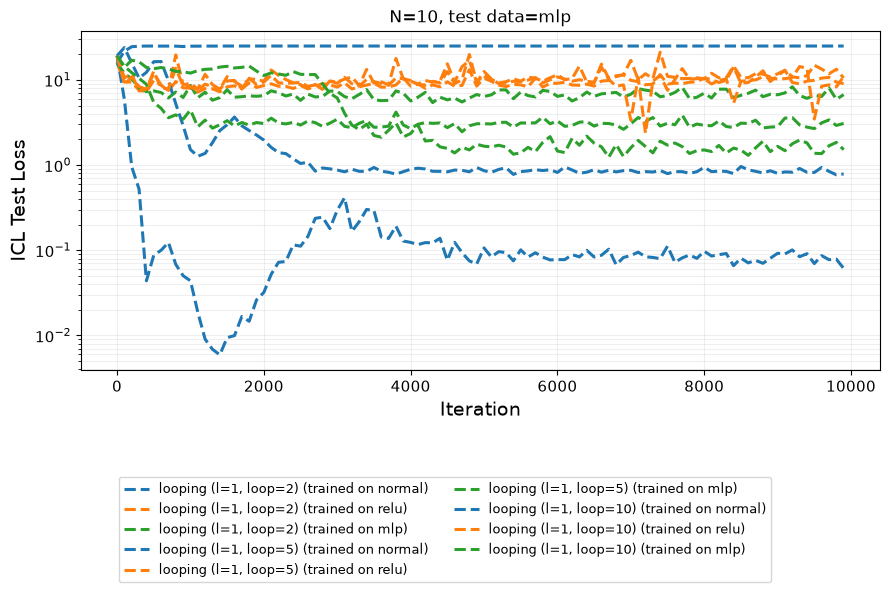

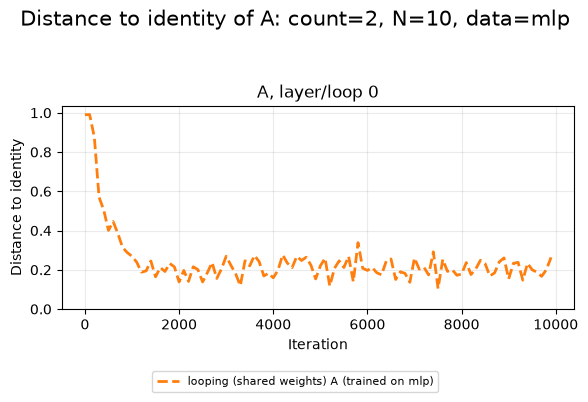

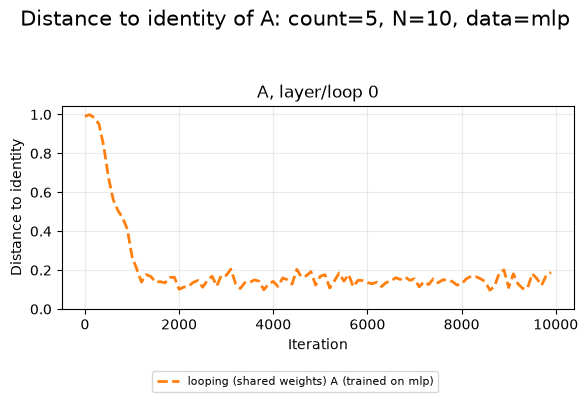

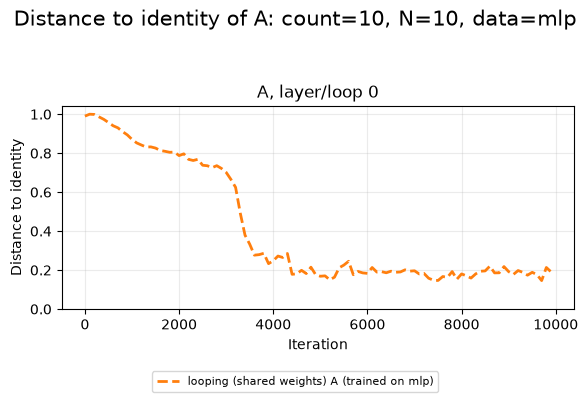

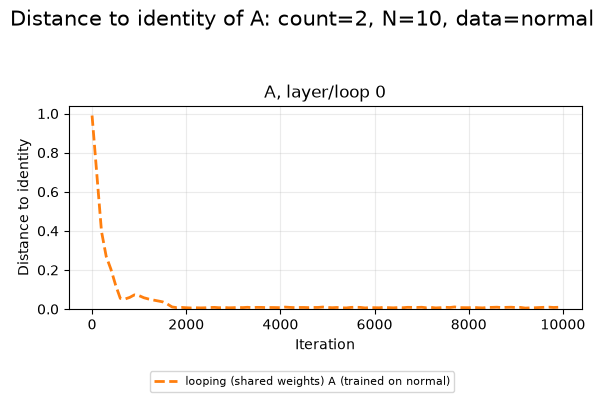

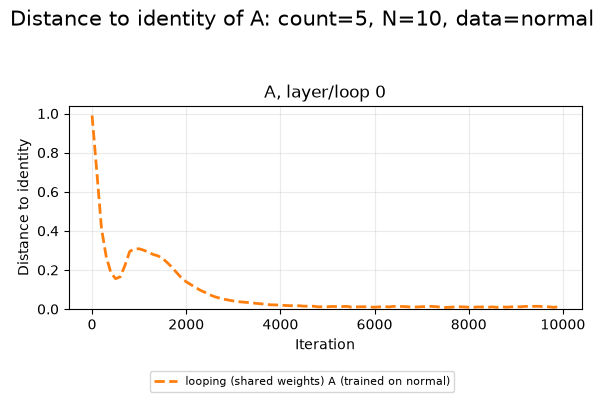

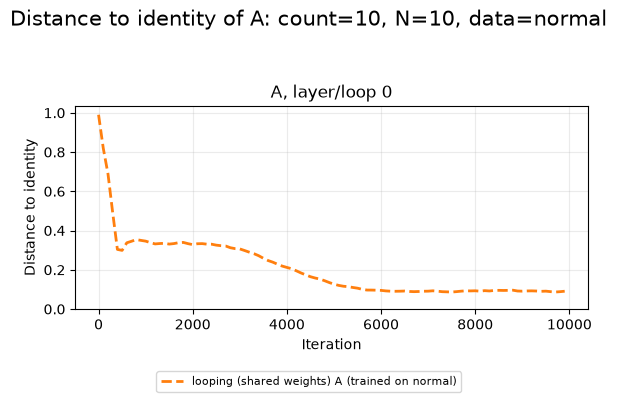

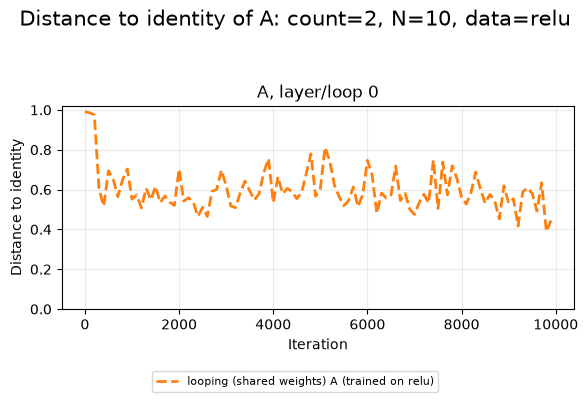

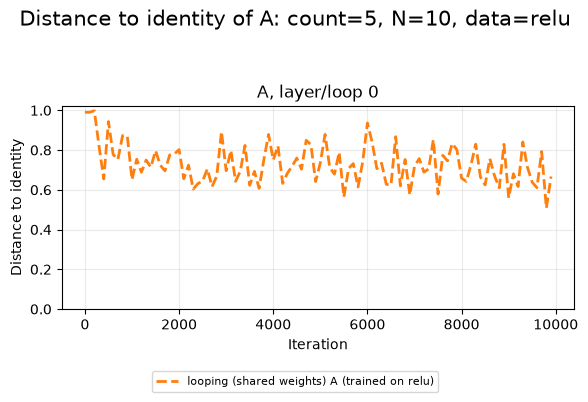

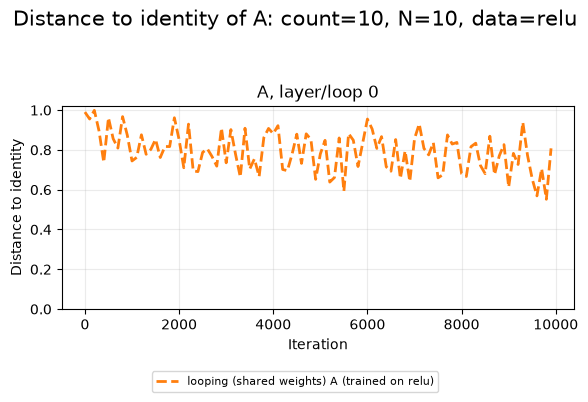

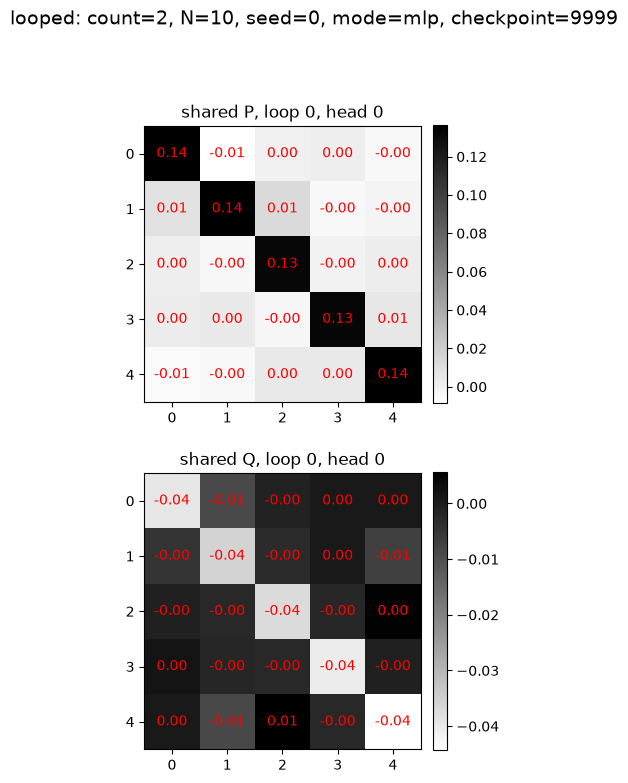

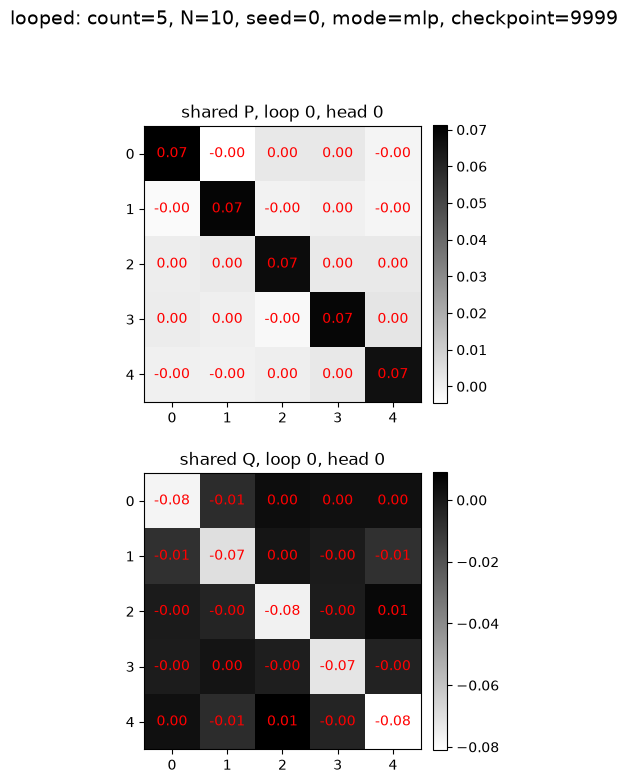

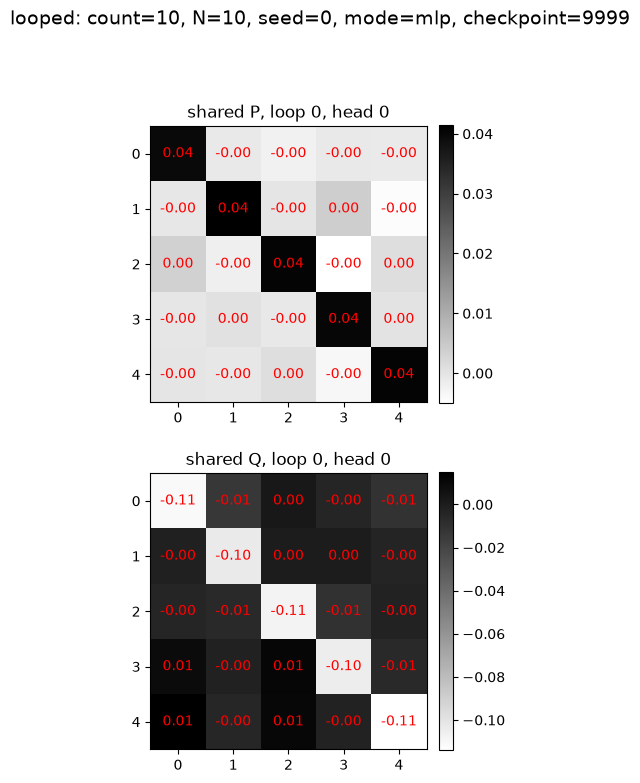

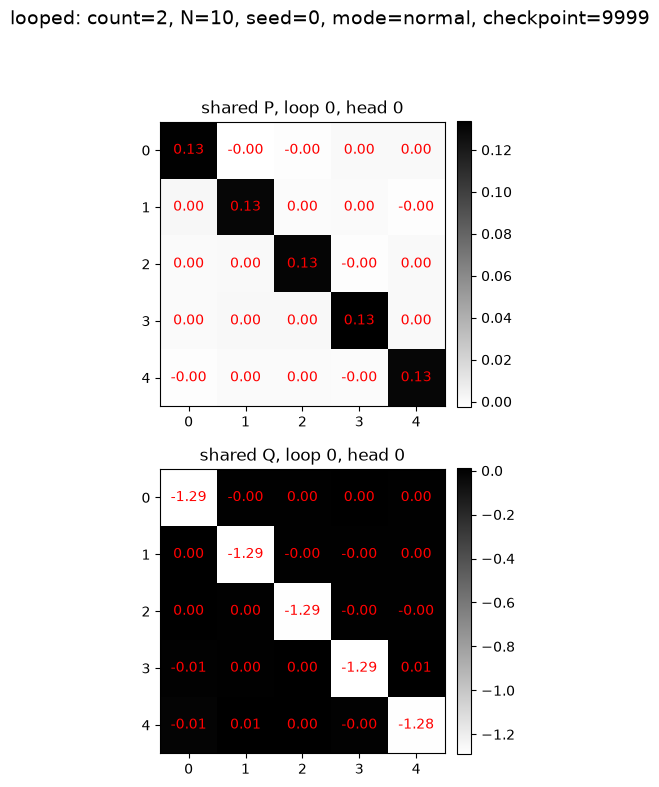

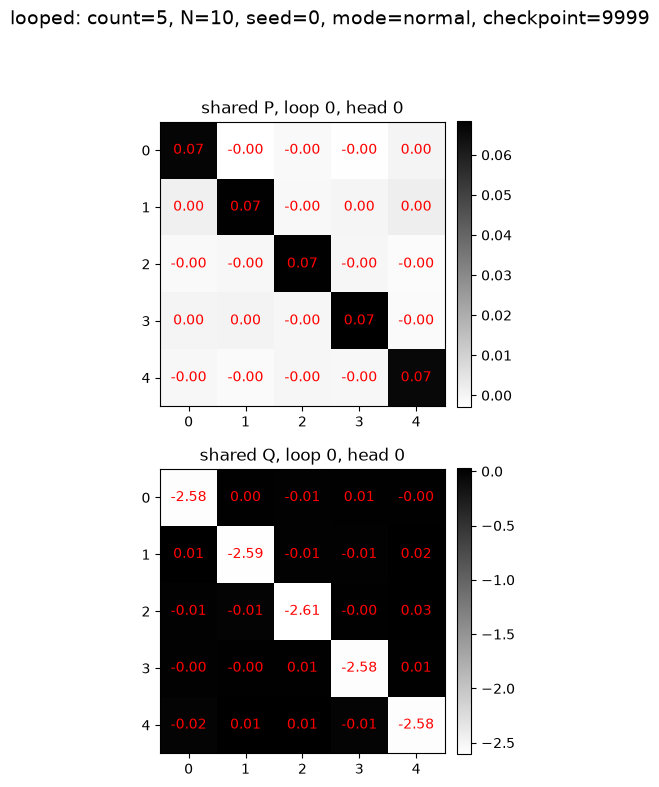

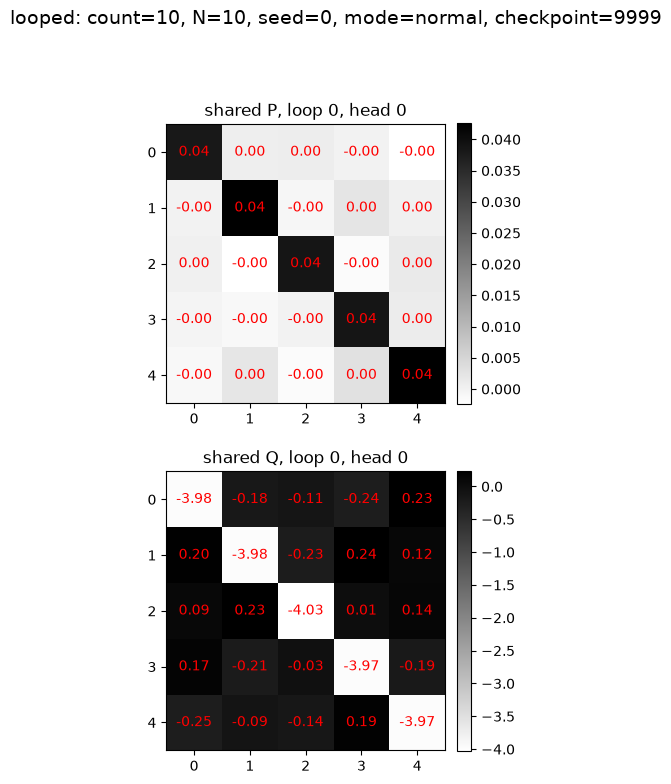

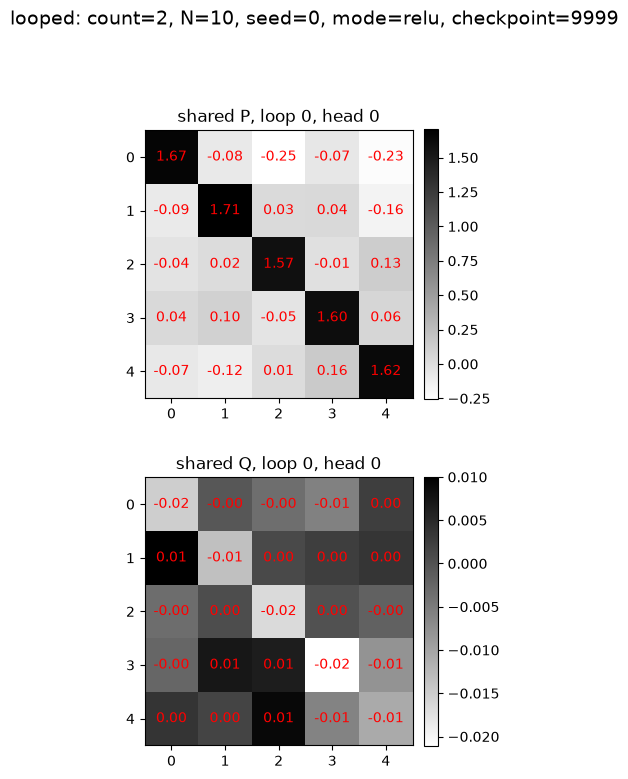

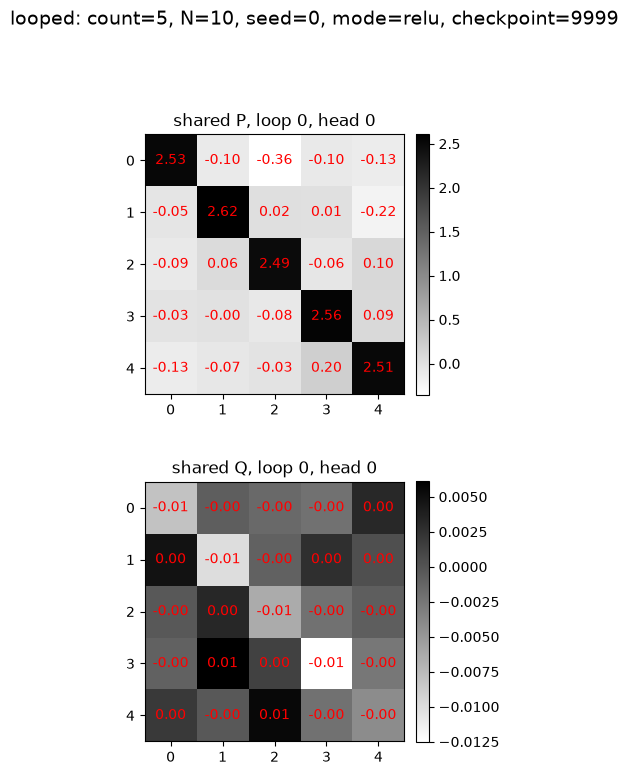

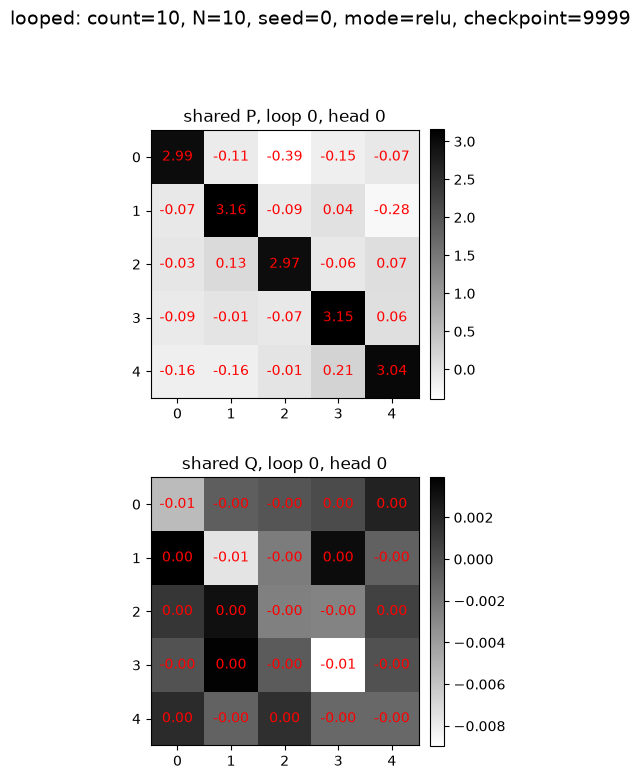

In [15]:
for test_data_mode, loss_dict in nonlinear_loss_dict.items():
    plot_loss_curves(
        loss_dict, loop_counts, model_types, iterations,
        fig_dir=nonlinear_fig_dir,
        filename='nonlinear_data_mode_test_loss.pdf',
        test_data_mode=test_data_mode,
    )
plot_dist_to_identity(
    nonlinear_dist_dict, loop_counts, iterations, fig_dir=nonlinear_fig_dir,
)
plot_parameter_matrices(
    nonlinear_hist_dict, seeds[0], loop_counts, model_types, n_head,
    hist_stride=hist_stride, fig_dir=nonlinear_fig_dir,
)
